# Практическая работа 4. MST, независимые множества, раскраска, знаковые графы, малый мир
Проверка ручных решений

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

## Задание 1. MST

In [2]:
G = nx.Graph()
G.add_weighted_edges_from([('A', 'B', 4), ('A', 'C', 7), ('A', 'D', 3), ('B', 'C', 5), ('B', 'D', 2),
                           ('B', 'E', 6), ('C', 'D', 5), ('D', 'E', 2), ('D', 'F', 1), ('E', 'F', 9)])
for alg in ['kruskal', 'prim']:
    T = nx.minimum_spanning_tree(G, algorithm=alg)
    print(alg, sorted(T.edges(data='weight')), 'вес =', T.size(weight='weight'))

kruskal [('A', 'D', 3), ('B', 'C', 5), ('B', 'D', 2), ('D', 'E', 2), ('D', 'F', 1)] вес = 13.0
prim [('A', 'D', 3), ('B', 'D', 2), ('C', 'D', 5), ('D', 'E', 2), ('D', 'F', 1)] вес = 13.0


## Задание 2. Жадное независимое множество

In [3]:
H = nx.Graph()
H.add_edges_from([('A', 'B'), ('A', 'C'), ('A', 'D'), ('B', 'D'), ('B', 'E'),
                  ('C', 'D'), ('C', 'E'), ('D', 'E'), ('E', 'F')])

def greedy_independent_set(G):
    G = G.copy()
    result = []
    step = 1
    while G.number_of_nodes() > 0:
        print('Шаг', step, 'степени:', dict(sorted(G.degree())))
        # берём вершину с минимальной степенью
        v = min(sorted(G.nodes()), key=lambda x: G.degree(x))
        result.append(v)
        G.remove_nodes_from(list(G.neighbors(v)) + [v])
        step += 1
    return result

print('Независимое множество:', greedy_independent_set(H))

Шаг 1 степени: {'A': 3, 'B': 3, 'C': 3, 'D': 4, 'E': 4, 'F': 1}
Шаг 2 степени: {'A': 3, 'B': 2, 'C': 2, 'D': 3}
Шаг 3 степени: {'C': 0}
Независимое множество: ['F', 'B', 'C']


## Задание 3. Вельш-Пауэлл

In [4]:
def welsh_powell(G):
    order = sorted(G.nodes(), key=lambda v: (-G.degree(v), v))
    print('Порядок вершин:', order)
    color = {}
    c = 0
    for v in order:
        if v in color:
            continue
        c += 1
        color[v] = c
        group = [v]
        for u in order:
            if u not in color and all(not G.has_edge(u, w) for w in group):
                color[u] = c
                group.append(u)
        print('Цвет', c, ':', group)
    return color

col = welsh_powell(H)
print('Число цветов:', max(col.values()))

Порядок вершин: ['D', 'E', 'A', 'B', 'C', 'F']
Цвет 1 : ['D', 'F']
Цвет 2 : ['E', 'A']
Цвет 3 : ['B', 'C']
Число цветов: 3


## Задание 4. Знаковый граф

In [5]:
S = nx.Graph()
for u, v, s in [(1, 2, '+'), (1, 3, '-'), (2, 3, '-'), (2, 4, '+'), (3, 4, '-'), (4, 5, '-'), (1, 5, '-')]:
    S.add_edge(u, v, sign=s)

balanced = True
for cyc in nx.simple_cycles(S):
    neg = 0
    for i in range(len(cyc)):
        if S[cyc[i]][cyc[(i + 1) % len(cyc)]]['sign'] == '-':
            neg += 1
    print(cyc, 'отрицательных рёбер:', neg)
    if neg % 2 == 1:
        balanced = False
print('Граф сбалансирован:', balanced)

[1, 2, 3] отрицательных рёбер: 2
[1, 2, 3, 4, 5] отрицательных рёбер: 4
[1, 2, 4, 3] отрицательных рёбер: 2
[1, 2, 4, 5] отрицательных рёбер: 2
[1, 3, 2, 4, 5] отрицательных рёбер: 4
[1, 3, 4, 5] отрицательных рёбер: 4
[2, 3, 4] отрицательных рёбер: 2
Граф сбалансирован: True


## Задание 5. Уоттс-Строгатц

Диаметр кольца: 4
Средняя длина пути: 2.286
После перенаправления диаметр: 4
Средняя длина пути: 2.179
Эксцентриситеты: {1: 4, 2: 4, 3: 3, 4: 4, 5: 3, 6: 2, 7: 3, 8: 4}


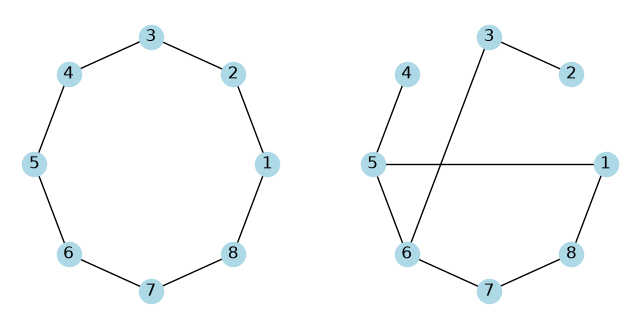

In [6]:
R = nx.cycle_graph(range(1, 9))
print('Диаметр кольца:', nx.diameter(R))
print('Средняя длина пути:', round(nx.average_shortest_path_length(R), 3))

# перенаправляем два ребра
R2 = R.copy()
R2.remove_edge(1, 2)
R2.add_edge(1, 5)
R2.remove_edge(3, 4)
R2.add_edge(3, 6)
print('После перенаправления диаметр:', nx.diameter(R2))
print('Средняя длина пути:', round(nx.average_shortest_path_length(R2), 3))
print('Эксцентриситеты:', nx.eccentricity(R2))

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
nx.draw_circular(R, with_labels=True, node_color='lightblue')
plt.subplot(1, 2, 2)
nx.draw_circular(R2, with_labels=True, node_color='lightblue')
plt.show()